# Lab 1 — Pipe flow and pump selection

Design a water-transfer line between two open tanks. Select a pipe and pump operating speed, then defend the energy implications.

## Design workshop: run → compare → decide

All numerical methods, loops, tables and plots are supplied. You only change
values in cells marked **DESIGN SETTINGS** and write your engineering decisions.
In Colab, these settings also have parameter forms. The small worked examples
may be rerun after changing the named example values; their equations are supplied.
Run each analysis as provided; its implementation is collapsed where supported
and can be expanded if you are curious. No Python programming is assessed.

Work through the notebook in order. After changing an upstream setting, rerun
that section and every section below it so results stay consistent. Restore the
printed base values to reproduce the reference case. Keep at least one rejected
design and explain why you rejected it. Each analysis table is evidence for a
decision, not a complete answer on its own.

**Time budget (six hours):** setup and system prediction 30 min; balances and
feasibility 75 min; operating policy and checks 90 min; alternative designs
75 min; robustness and break 45 min; recommendation 45 min. The supplied
worked example belongs within the feasibility block, not an extra activity.

**Time budget: 6 hours, including a short break and submission.** Work in pairs,
but both partners must be able to explain every figure and calculation.
Prerequisites: material and energy balances, algebra, and reading tables and plots. No Python programming is required.
Use SI units unless explicitly stated. All case data are synthetic teaching values,
not measurements or validated equipment specifications.

Submit this notebook with outputs and a short engineering recommendation (300–500 words).
Include assumptions, a labelled flowsheet, equations, units, balance checks,
at least one sensitivity plot, and a discussion of model limitations.
Optional extensions are outside the six-hour budget.

## 1. Setup and prediction — 30 minutes
Before computing, sketch the apparatus and predict which parameter most strongly
affects its size or energy demand. Explain your reasoning in two sentences.

Locally, place `helpers.py` beside this notebook and install the root requirements.
In Colab, upload both files using the Files panel. Alternatively, after the repository
is published, set `HELPER_URL` below to the raw GitHub URL of this lab's `helpers.py`.
Use a commit SHA in the URL for reproducible teaching. Only download code from a
repository you trust. Each lab needs only its own helper file.

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

HELPER_URL = ""  # e.g. https://raw.githubusercontent.com/OWNER/REPO/COMMIT/lab_01_flow/helpers.py
if not Path("helpers.py").exists():
    if not HELPER_URL:
        raise FileNotFoundError("Upload this lab's helpers.py or set HELPER_URL, then rerun.")
    urlretrieve(HELPER_URL, "helpers.py")

import numpy as np
import matplotlib.pyplot as plt
import helpers as h

## See the whole system

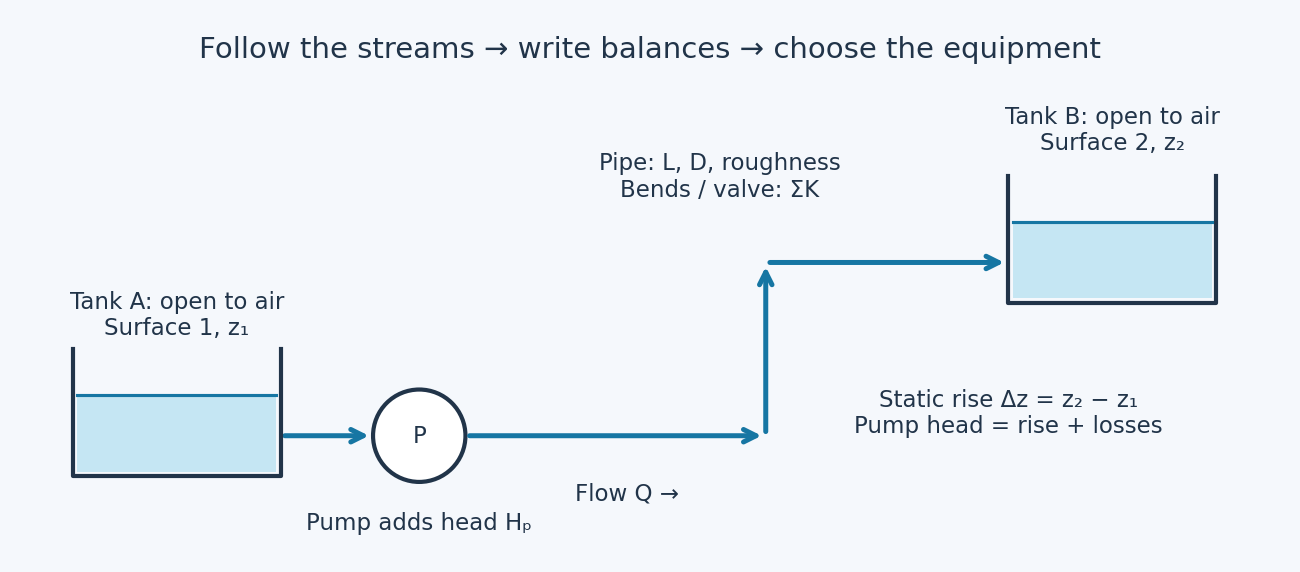

Schematic only: equipment sizes, heights and pipe lengths are not to scale.
Trace each stream with your finger. Identify what enters, what leaves, and where
energy is added or removed. Match the labels to the variables in the model below.

## Model and assumptions
    Steady, incompressible, isothermal flow; large open tanks; negligible tank velocities.
    $v=4Q/(\pi D^2)$, $Re=\rho vD/\mu$.
    Use the **Darcy** friction factor (four times the Fanning factor):
    $H_s=\Delta z+(fL/D+\sum K)v^2/(2g)$.
    Laminar: $f=64/Re$. For turbulent flow the helper uses the explicit Haaland
    approximation. The transition region 2300–4000 is deliberately rejected: flag
    those cases instead of silently applying a correlation.
    The illustrative pump curve is $H_p=s^2H_0-aQ^2$, with speed ratio $s$.
    Hydraulic power is $\rho gQH$ and shaft power is hydraulic power divided by efficiency.
    This curve is a teaching model; it does not establish NPSH margin or a safe pump envelope.

### Worked example: one pipe and one trial flow
Follow the diagram from Tank A through the pump and pipe to Tank B. The pump
must supply both the elevation rise and the losses. Start by testing **one** flow;
it is not yet the operating point. The code below prints each part separately.
At 3 L/s you should find a velocity near 0.904 m/s and a system head near 14.0 m.
The pump supplies 26.5 m, so the actual intersection should lie at a higher flow.

In [ ]:
ex_Q = 3.0 / 1000  # convert L/s to m³/s before using SI equations
ex_D, ex_L, ex_rise = 0.065, 120.0, 12.0
ex_v = ex_Q / (np.pi * ex_D**2 / 4)
ex_Re = 998.0 * ex_v * ex_D / 0.001
ex_f = float(h.friction_factor(ex_Re, 4.5e-5 / ex_D))
ex_pipe_loss = ex_f * ex_L / ex_D * ex_v**2 / (2 * 9.81)
ex_fitting_loss = 8.0 * ex_v**2 / (2 * 9.81)
ex_required = ex_rise + ex_pipe_loss + ex_fitting_loss
ex_available = float(h.pump_head(ex_Q))
print(f"Velocity = {ex_v:.3f} m/s; Re = {ex_Re:.0f}; Darcy f = {ex_f:.4f}")
print(f"Rise = {ex_rise:.2f} m; pipe loss = {ex_pipe_loss:.2f} m; fittings = {ex_fitting_loss:.2f} m")
print(f"Required = {ex_required:.2f} m; pump = {ex_available:.2f} m")
print(f"Head surplus = {ex_available-ex_required:.2f} m")

**Try a small change:** Copy the cell and change only ex_D to 0.050 m. Predict the direction of the loss change first. Then change the trial flow to 4 L/s. Which term changes most?

Spend about 20 minutes on this example within the model-development time below. Predict → run → explain. Then move to the main case.

### Main design case

The next cell defines the larger case used in the assessed tasks. Example variables use `ex_` so you can rerun them without changing this case.

In [ ]:
rho, mu, g = 998.0, 1.0e-3, 9.81
length, rise, roughness, K = 120.0, 12.0, 4.5e-5, 8.0
diameter = 0.065
H0, a, efficiency = 40.0, 1.5e6, 0.70  # a has units s²/m⁵
Q = np.linspace(0.001, 0.007, 150)  # m³/s
system = h.system_head(Q, diameter, length, rise, roughness, K, rho, mu)
plt.plot(Q * 1000, system, label="System")
plt.plot(Q * 1000, h.pump_head(Q, H0, a), label="Pump")
plt.xlabel("Flow / L s$^{-1}$"); plt.ylabel("Head / m"); plt.legend(); plt.grid()

## 2. Understand the energy requirement — 75 minutes

Use the supplied contribution calculation at 3 L/s. On the system diagram,
identify where the pump adds energy and where energy is dissipated. Check one
velocity or loss term with a calculator and explain pressure versus head.
Which part of the required head could a larger pipe reduce? Which part remains
even at negligible flow? Predict the effect of a smaller pipe before changing
the diameter in the settings cell. Record a prediction and the observed result.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# m; try 0.050, then restore the base case
diameter = 0.065 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
trial_q = .003
velocity = 4*trial_q/(np.pi*diameter**2)
reynolds = rho*velocity*diameter/mu
# Independent evaluation of the stated Haaland correlation.
darcy_f = (-1.8*np.log10((roughness/diameter/3.7)**1.11 + 6.9/reynolds))**-2
pipe_loss = darcy_f*length/diameter*velocity**2/(2*g)
fitting_loss = K*velocity**2/(2*g)
hand_head = rise + pipe_loss + fitting_loss
reference_head = float(h.system_head(trial_q, diameter, length, rise, roughness, K, rho, mu))
assert np.isclose(hand_head, reference_head)
print(f"v = {velocity:.6f} m/s; Re = {reynolds:.1f}; f_D = {darcy_f:.6f}")
print(f"Pipe = {pipe_loss:.6f} m; fittings = {fitting_loss:.6f} m; total = {hand_head:.6f} m")
print(f"Equivalent pressure rise = {rho*g*hand_head/1000:.3f} kPa")
print(f"Helper mismatch = {hand_head-reference_head:.3e} m; zero-flow limit = {rise:.1f} m")

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 3. Decide whether the base pump meets the duty — 90 minutes

Run the supplied operating-point search. Mark the operating point on
the curves and decide whether the base system meets the required throughput.
Report flow, head, annual energy and energy per cubic metre. What does the
head-residual check tell you, and what does it leave uncertain? If the requirement
changes from 3 to 4.5 L/s, would this base pump/pipe combination still qualify?
No bisection code is required: explain the physical meaning of the intersection.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# L/s; try 4.5
required_flow_Lps = 3.0 #@param {type:"number"}
# hours/year
operating_hours = 4000 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
system = h.system_head(Q,diameter,length,rise,roughness,K,rho,mu)
def bisect_root(function, low, high, tolerance=1e-6, max_iterations=200):
    f_low, f_high = function(low), function(high)
    if f_low == 0:
        return low
    if f_high == 0:
        return high
    if not np.isfinite([f_low, f_high]).all() or f_low*f_high > 0:
        raise ValueError("A finite sign-changing bracket is required")
    for iteration in range(max_iterations):
        mid = (low+high)/2
        f_mid = function(mid)
        if not np.isfinite(f_mid):
            raise ValueError("Nonfinite residual")
        if abs(f_mid) < tolerance:
            return mid
        if f_low*f_mid < 0:
            high = mid
        else:
            low, f_low = mid, f_mid
    raise ValueError("Bisection did not converge")

def operating_point(D, speed=1.0, eps=roughness, eta=efficiency):
    if not 0 < eta <= 1:
        raise ValueError("Efficiency must lie in (0, 1]")
    def residual(q):
        return float(h.pump_head(q, H0, a, speed) -
                     h.system_head(q, D, length, rise, eps, K, rho, mu))
    # Lower end remains turbulent for every D in this exercise.
    low, high = .001, speed*np.sqrt(H0/a)
    flow = bisect_root(residual, low, high)
    head = float(h.pump_head(flow, H0, a, speed))
    shaft = rho*g*flow*head/eta
    assert abs(residual(flow)) < .001
    return flow, head, shaft, shaft/flow/3.6e6  # m³/s, m, W, kWh/m³

base_q, base_h, base_power, base_specific = operating_point(diameter)
print("Meets flow requirement:", base_q*1000 >= required_flow_Lps)
print(f"Operating flow = {base_q*1000:.6f} L/s; head = {base_h:.6f} m")
print(f"Shaft power = {base_power:.3f} W; annual energy = {base_power/1000*operating_hours:.2f} kWh")
print(f"Specific energy = {base_specific:.6f} kWh/m³")
plt.figure(figsize=(7, 4))
plt.plot(Q*1000, system, label="System")
plt.plot(Q*1000, h.pump_head(Q, H0, a), label="Pump")
plt.scatter([base_q*1000], [base_h], color="black", label="Operating point")
plt.xlabel("Flow / L s$^{-1}$"); plt.ylabel("Head / m"); plt.legend(); plt.grid(); plt.show()

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 4. Select a pipe and pump speed — 75 minutes

Use the supplied nine-candidate table to shortlist feasible designs.
Choose a pipe diameter and speed in the settings cell, then compare your choice
with the feasible candidate using least electricity per delivered volume.
Report throughput margin and specific energy. Explain whether you would accept
a larger pipe without its purchase price, and whether a low-power design that
fails the flow requirement should remain on the shortlist. State your selection
criterion explicitly; more than one defended recommendation is possible.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# m: choose 0.050, 0.065 or 0.080
selected_diameter = 0.080 #@param {type:"number"}
# choose 0.8, 1.0 or 1.1
selected_speed = 1.0 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
designs = []
print("D / m  speed   flow / L/s  shaft / W  kWh/m³     meets duty")
for D in [.050, .065, .080]:
    for speed in [.8, 1.0, 1.1]:
        flow, head, power, specific = operating_point(D, speed)
        designs.append((D, speed, flow, head, power, specific))
        print(f"{D:.3f}   {speed:.1f}     {flow*1000:8.4f}   {power:8.2f}  {specific:.6f}   {flow*1000 >= required_flow_Lps}")
feasible_designs = [row for row in designs if row[2]*1000 >= required_flow_Lps]
if feasible_designs:
    best = min(feasible_designs, key=lambda row: row[5])
    print(f"Lowest specific-energy feasible candidate: D={best[0]:.3f} m, speed={best[1]:.1f}")
else:
    print("None of the candidates meets the requested duty")
chosen_D, chosen_speed = selected_diameter, selected_speed
chosen_result = operating_point(chosen_D, chosen_speed)
print(f"Your selection: {chosen_result[0]*1000:.4f} L/s; margin={chosen_result[0]*1000-required_flow_Lps:.4f} L/s")
print(f"Your selection: {chosen_result[3]:.6f} kWh/m³; feasible={chosen_result[0]*1000 >= required_flow_Lps}")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for D in [.050, .065, .080]:
    rows = np.array([row for row in designs if row[0] == D])
    axes[0].plot(rows[:, 1], rows[:, 2]*1000, 'o-', label=f"D={D:.3f} m")
    axes[1].plot(rows[:, 1], rows[:, 5], 'o-', label=f"D={D:.3f} m")
axes[0].axhline(required_flow_Lps, color='black', linestyle=':', label='Required flow')
axes[0].set_ylabel("Operating flow / L s$^{-1}$")
axes[1].set_ylabel("Specific energy / kWh m$^{-3}$")
for axis in axes:
    axis.set_xlabel("Speed ratio / dimensionless"); axis.legend(); axis.grid()
plt.tight_layout(); plt.show()

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 5. Check robustness before recommending — 45 minutes

Take a 10-minute break. Run the supplied roughness and efficiency
sweeps for your selected design. Is it feasible at the worst roughness?
Which uncertainty changes specific energy most over these stated ranges?
Explain why efficiency changes power without moving the operating point in
this particular model. Name the pump and suction data you would request before
procurement. Revise your selection if its margin is inadequate.

**How to work:** Run the supplied analysis cell, read its table and plot,
then answer the decision questions in words. If this section has a settings cell,
change only those values and rerun this section and all following sections.
No numerical routines or plotting code need to be written. A failed constraint
is a result to discuss, not something to hide. Keep units with every reported value.

In [ ]:
#@title DESIGN SETTINGS — edit values or use the Colab form
# m
roughness_low = 1e-6 #@param {type:"number"}
# m
roughness_high = 2e-4 #@param {type:"number"}
efficiency_low = 0.55 #@param {type:"number"}
efficiency_high = 0.80 #@param {type:"number"}

In [ ]:
#@title SUPPLIED ANALYSIS — run as provided; no edits needed
roughness_values = np.unique(np.r_[np.linspace(roughness_low, roughness_high, 25), roughness])
eta_values = np.unique(np.r_[np.linspace(efficiency_low, efficiency_high, 25), efficiency])
rough_results = np.array([operating_point(chosen_D, chosen_speed, eps=value)
                          for value in roughness_values])
eta_results = np.array([operating_point(chosen_D, chosen_speed, eta=value)
                        for value in eta_values])
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].plot(roughness_values*1e6, rough_results[:, 0]*1000)
axes[0].axhline(required_flow_Lps, color='black', linestyle=':')
axes[0].set(xlabel="Roughness / µm", ylabel="Operating flow / L s$^{-1}$")
axes[1].plot(roughness_values*1e6, rough_results[:, 3])
axes[1].set(xlabel="Roughness / µm", ylabel="Specific energy / kWh m$^{-3}$")
axes[2].plot(eta_values, eta_results[:, 3])
axes[2].set(xlabel="Efficiency / dimensionless", ylabel="Specific energy / kWh m$^{-3}$")
for axis in axes:
    axis.grid()
plt.tight_layout(); plt.show()
rough_change = (rough_results[:, 3].max()/rough_results[:, 3].min()-1)*100
eta_change = (eta_results[:, 3].max()/eta_results[:, 3].min()-1)*100
print(f"Specific-energy span: roughness {rough_change:.2f}%; efficiency {eta_change:.2f}% (max/min - 1)")
print(f"Minimum flow across roughness sweep: {rough_results[:,0].min()*1000:.4f} L/s")
assert np.allclose(eta_results[:, 0], eta_results[0, 0])
# Check all designs at worst roughness before declaring a robust candidate.
robust = [row for row in designs if operating_point(row[0], row[1], eps=roughness_high)[0]*1000 >= required_flow_Lps]
if robust:
    robust_choice = min(robust, key=lambda row: row[5])
    print(f"Robust to stated roughness range: D={robust_choice[0]:.3f} m, speed={robust_choice[1]:.1f}")
else:
    print("No candidate meets the requirement at maximum roughness")

**Your design decision — complete in words:**

1. **Prediction / requirement:** …
2. **Evidence:** Report at least two numbers from the table or plot, with units.
3. **Decision and tradeoff:** …
4. **What could change the decision?** State an assumption or missing measurement.

You are assessed on engineering reasoning, not on writing Python.

## 6. Engineering recommendation and submission — 45 minutes
Choose a design and support it with numbers. State what would need measuring before
using it in practice. Check your balances and inspect every axis label and unit.
Restart the kernel and run all completed cells in order before submission.

**Peer check:** Ask your partner to explain one equation, one numerical check,
and one reason the model could fail. Record any revision this discussion prompted.

**Design-review checklist:** Does your selected design meet every stated
requirement? Include its operating margin, one rejected alternative and a
numerical reason for rejection. Distinguish a model verification check from
evidence that real equipment will perform as predicted. Identify the next
measurement or vendor datum needed. No new code is required for submission.

## Optional design-review extension

No coding is required. Would two identical parallel pumps double the delivered flow? Sketch the combined pump curve against the rising system curve and explain your answer.